# Reproducing Rogers (2025), Figures 1 & 2

**"On the road to the radius valley: distinguishing between gas dwarfs and water worlds with young transiting exoplanets"** (Rogers 2025, arXiv:2503.17364).

This notebook re-implements the *simple semi-analytic radiative–convective model* of Section 2 and reproduces:

* **Figure 1** — transit-radius evolution of a sub-Neptune envelope for different bulk mean molecular weights $\mu = 2.35, 5.0, 10, 18$ amu (fixed $5\,M_\oplus$ Earth-like core, $X\equiv M_{\rm env}/M_{\rm c}=0.01$, $T_{\rm eq}=800$ K).
* **Figure 2** — radius evolution of **gas dwarfs** (H$_2$/He envelopes, $\mu=2.35$, Earth-like core) vs **water worlds** (steam envelopes, $\mu=18$, water-rich core) for core masses $4, 6, 8\,M_\oplus$.

Radius decrease as a function of time is due to thermal cooling and contraction (no mass loss).

## Model summary (Section 2)

Adiabatic convective envelope density profile (Eq. 1):
$$\rho(r)=\rho_{\rm rcb}\left[1+\nabla_{\rm ad}\frac{GM_{\rm c}}{c_{\rm s}^2 R_{\rm rcb}}\left(\frac{R_{\rm rcb}}{r}-1\right)\right]^{1/(\gamma-1)},\qquad \nabla_{\rm ad}=\frac{\gamma-1}{\gamma},\qquad c_{\rm s}^2=\frac{k_{\rm B}T_{\rm eq}}{\mu m_{\rm H}}$$
with $T(r)=T_{\rm eq}\,[\,\cdot\,]$ (same bracket, power 1).

Evolution ODEs (Eqs. 3–4), with no mass loss ($\dot M=0$, so $X$ constant):
$$\frac{dM_{\rm env}}{dt}=-\dot M,\qquad \frac{dE_{\rm p}}{dt}=-L_{\rm rad}$$

Radiative luminosity (Eq. 5):
$$L_{\rm rad}=\frac{64\pi\,\nabla_{\rm ad}\,G M_{\rm p}\,\sigma T_{\rm eq}^4}{3\,c_{\rm s}^2\,\kappa_{\rm rcb}\,\rho_{\rm rcb}}$$

Envelope mass (Eq. 6) and planet energy (Eq. 8):
$$M_{\rm env}=\int_{R_{\rm c}}^{R_{\rm out}}4\pi r^2\rho\,dr,\quad E_{\rm p}=\int_{R_{\rm c}}^{R_{\rm out}}4\pi r^2\rho\left(\frac{k_{\rm B}T}{\mu m_{\rm H}(\gamma-1)}-\frac{GM_{\rm c}}{r}\right)dr+\frac{M_{\rm c}k_{\rm B}T_{\rm c}}{\mu_{\rm c}m_{\rm H}(\gamma_{\rm c}-1)}$$

Isothermal scale height $H\propto 1/\mu$ (Eq. 12) is what makes low-$\mu$ gas dwarfs puffy at young ages.

### Simplifications relative to the paper (clearly noted)
Reproducing the paper *exactly* needs external tables that are not bundled here. This notebook substitutes tractable, physically faithful approximations:
1. **Opacity** — a constant Rosseland mean $\kappa_{\rm rcb}$ (the paper interpolates Kempton et al. 2023 tables; its own Fig. 5 uses constant-$\kappa$ runs).
2. **Core radius** — a simple $R_{\rm c}\propto M_{\rm c}^{0.27}$ scaling (paper uses Fortney et al. 2007 tables).
3. **$T_{\rm eq}$** — held constant (paper folds in Johnstone et al. 2021 pre-main-sequence stellar dimming).
4. **Initial condition** — set the cooling time $\tau_{\rm cool}\simeq|E_{\rm p}|/L_{\rm rad}$ equal to the start age (Eq. 10 spirit).
5. **Transit radius** — isothermal atmosphere above $R_{\rm rcb}$ integrated to chord optical depth $\tau=1$ (Guillot 2010 style).

These preserve the key physics and reproduce the *qualitative and semi-quantitative* trends of Figs. 1 & 2.

Transit radius $R_{\rm t}$ — what a transit observation actually measures: the radius at which the atmosphere becomes opaque to starlight along the grazing chord through the limb. Because the sightline skims
  tangentially through far more gas than a radial path, the chord optical depth reaches 1 higher up than the radial photosphere.

  So $R_{\rm t} > R_{\rm ph} > R_{\rm rcb}$, and the gaps between them are roughly a few atmospheric scale heights $H$.

  Why this matters here: the difference is set by $H \propto 1/\mu$ and grows when the planet is hot and puffy. Rogers (2025) explicitly notes "the difference between photospheric and transit radii of young
  planets with large scale heights can become significant," which is why the paper (and the notebook) report the transit radius — it's both the largest of these and the one you compare against observed transiting
  planets. For an old, high-$\mu$ (steam) planet with a tiny scale height, all three nearly coincide; for a young, low-$\mu$ (H₂/He) gas dwarf they can differ by a noticeable fraction of $R_\oplus$.

  In the notebook this is the R_transit function: it integrates the isothermal atmosphere above $R_{\rm rcb}$ and finds where the chord optical depth $\kappa,\rho,\sqrt{2\pi r H}=1$, which sits a few $H$ above
  $R_{\rm rcb}$.

In [1]:
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, optimize

# --- load project matplotlib config (rcParams.txt) ---
with open('../rcParams.txt') as f:
    for name, value in csv.reader(f):
        if name == 'name':
            continue
        try:
            value = int(value)
        except ValueError:
            try:
                value = float(value)
            except ValueError:
                pass
        try:
            plt.rcParams[name] = value
        except Exception:
            pass
print('matplotlib configured from rcParams.txt')

matplotlib configured from rcParams.txt


In [2]:
# ============================================================
#  Rogers (2025) simple radiative-convective sub-Neptune model
#  (CGS units throughout)
# ============================================================
G     = 6.674e-8      # cm^3 g^-1 s^-2
kB    = 1.381e-16     # erg/K
mH    = 1.6726e-24    # g
sigma = 5.670e-5      # erg cm^-2 s^-1 K^-4
Mearth = 5.972e27     # g
Rearth = 6.371e8      # cm
Myr    = 3.156e13     # s


def core_radius(Mc_e, kind):
    """Simple mass-radius scaling (SIMPLIFICATION of Fortney et al. 2007).
    'earth' = 25% Fe / 75% silicate; 'water' = 50% rock / 50% water (puffier)."""
    factor = 1.30 if kind == 'water' else 1.0
    return Rearth * factor * Mc_e ** 0.27


def make_planet(Mc_e, Teq, mu, gamma, kappa, kind, mu_c, gamma_c=4.0 / 3.0, X=0.01):
    """Build the structure/luminosity functions for one planet model."""
    Mc   = Mc_e * Mearth
    Rc   = core_radius(Mc_e, kind)
    Menv = X * Mc
    cs2  = kB * Teq / (mu * mH)
    nab  = (gamma - 1.0) / gamma            # adiabatic gradient
    RBp  = G * Mc / cs2                      # GM/cs^2
    RB   = G * Mc / (2.0 * cs2)              # Bondi radius

    def brak(r, Rrcb):                       # adiabat bracket term, Eq. 1
        return np.maximum(1.0 + nab * (RBp / Rrcb) * (Rrcb / r - 1.0), 1e-30)

    def props(Rrcb):
        """Given R_rcb solve rho_rcb from M_env, return (E_p, rho_rcb, L_rad)."""
        A = integrate.quad(lambda r: 4 * np.pi * r * r * brak(r, Rrcb) ** (1 / (gamma - 1)),
                           Rc, Rrcb, limit=80)[0]
        rho = Menv / A                       # rho_rcb (mass integral is linear in it)
        B = integrate.quad(
            lambda r: 4 * np.pi * r * r * brak(r, Rrcb) ** (1 / (gamma - 1)) *
            (kB * Teq * brak(r, Rrcb) / (mu * mH * (gamma - 1)) - G * Mc / r),
            Rc, Rrcb, limit=80)[0]
        Tc  = Teq * brak(Rc, Rrcb)
        Ep  = rho * B + Mc * kB * Tc / (mu_c * mH * (gamma_c - 1))   # Eq. 8
        L   = 64 * np.pi * nab * G * Mc * sigma * Teq ** 4 / (3 * cs2 * kappa * rho)  # Eq. 5
        return Ep, rho, L

    def R_transit(Rrcb, rho):
        """Isothermal atmosphere above R_rcb (Eq. 2); chord optical depth = 1."""
        def tau_chord(r):
            rho_r = rho * np.exp((G * Mc / cs2) * (1 / r - 1 / Rrcb))
            H = cs2 * r * r / (G * Mc)
            return kappa * rho_r * np.sqrt(2 * np.pi * r * H)
        if tau_chord(Rrcb) < 1:
            return Rrcb
        try:
            return optimize.brentq(lambda r: tau_chord(r) - 1.0, Rrcb, 10 * Rrcb)
        except Exception:
            return Rrcb

    return dict(Mc=Mc, Rc=Rc, RB=RB, props=props, R_transit=R_transit)


def evolve(m, t0=1.0, t1=5000.0, n=70):
    """Integrate dE_p/dt = -L_rad using R_rcb as the state variable.
    Returns (ages[Myr], transit radius[R_earth])."""
    def tau_cool(Rrcb):
        Ep, rho, L = m['props'](Rrcb)
        return abs(Ep) / L / Myr
    # initial condition: tau_cool(R0) = t0
    R0 = optimize.brentq(lambda R: tau_cool(R) - t0, m['Rc'] * 1.1, m['RB'] * 0.999)

    def dEp_dR(Rrcb):
        h = Rrcb * 1e-4
        return (m['props'](Rrcb + h)[0] - m['props'](Rrcb - h)[0]) / (2 * h)

    def rhs(t, y):
        return [-m['props'](y[0])[2] * Myr / dEp_dR(y[0])]   # dR_rcb/dt

    floor = lambda t, y: y[0] - m['Rc'] * 1.02
    floor.terminal = True
    floor.direction = -1
    sol = integrate.solve_ivp(rhs, [t0, t1], [R0],
                              t_eval=np.logspace(np.log10(t0), np.log10(t1), n),
                              rtol=1e-5, atol=1e4, events=floor, max_step=300)
    ages = sol.t
    Rt = np.array([m['R_transit'](R, m['props'](R)[1]) / Rearth for R in sol.y[0]])
    return ages, Rt

print('model ready')

model ready


## Figure 1 — transit radius evolution vs. bulk mean molecular weight

Fixed $5\,M_\oplus$ Earth-like core, $X=0.01$, $T_{\rm eq}=800$ K, no mass loss. Lower $\mu$ → larger scale height → puffier when young; all curves converge as the planet cools, so the spread is largest at the youngest ages.

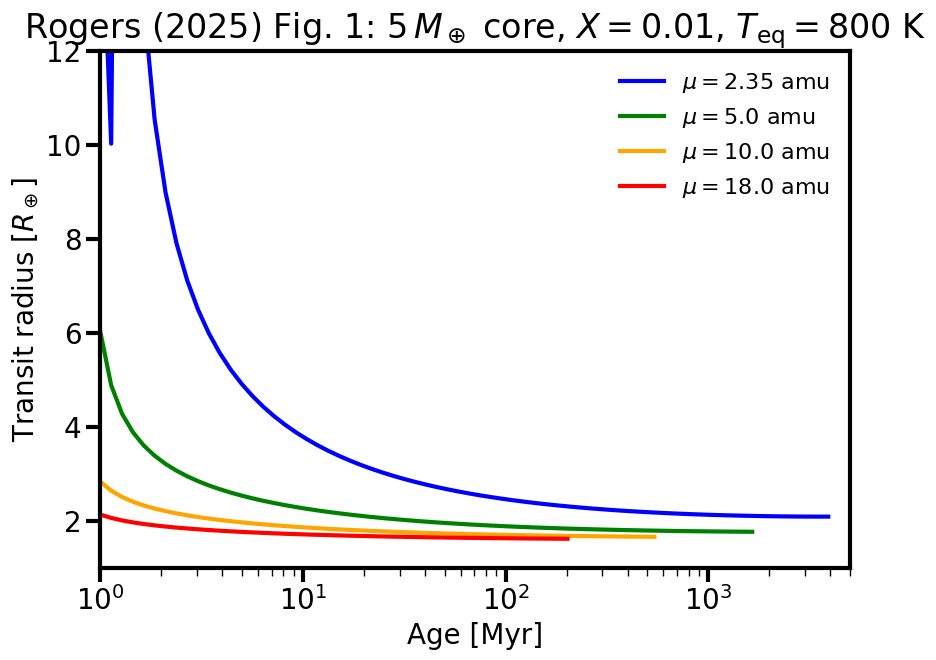

In [3]:
mu_cases = [(2.35, 'blue'), (5.0, 'green'), (10.0, 'orange'), (18.0, 'red')]
GAMMA_F1 = 7.0 / 5.0   # fixed adiabatic index to isolate the mean-molecular-weight effect

fig, ax = plt.subplots(figsize=(9, 7))
for mu, color in mu_cases:
    m = make_planet(Mc_e=5, Teq=800.0, mu=mu, gamma=GAMMA_F1,
                    kappa=0.1, kind='earth', mu_c=60.0)
    ages, Rt = evolve(m, t0=1.0, t1=5000.0)
    ax.plot(ages, Rt, color=color, lw=3, label=rf'$\mu = {mu}$ amu')

ax.set_xscale('log')
ax.set_xlabel('Age [Myr]')
ax.set_ylabel(r'Transit radius [$R_\oplus$]')
ax.set_xlim(1, 5000)
ax.set_ylim(1, 12)
ax.legend(frameon=False, fontsize=16)
ax.set_title(r'Rogers (2025) Fig. 1: $5\,M_\oplus$ core, $X=0.01$, $T_{\rm eq}=800$ K')
fig.tight_layout()
fig.savefig('../figures/rogers2025_fig1_mmw.png', dpi=200, bbox_inches='tight')
plt.show()

## Figure 2 — gas dwarfs vs. water worlds

**Gas dwarfs** (orange): Earth-like core ($\mu_{\rm c}=60$), H$_2$/He envelope ($\mu=2.35$, $\gamma=7/5$).
**Water worlds** (blue): water-rich core ($\mu_{\rm c}=27$), steam envelope ($\mu=18$, $\gamma=4/3$).
Line styles show core masses $4/6/8\,M_\oplus$ (solid/dashed/dotted). Gas dwarfs are large and puffy when young and contract strongly; water worlds stay compact and nearly flat. The two only converge at Gyr ages — the divergence at early ages is the paper's key diagnostic. Radius is only weakly sensitive to core mass.

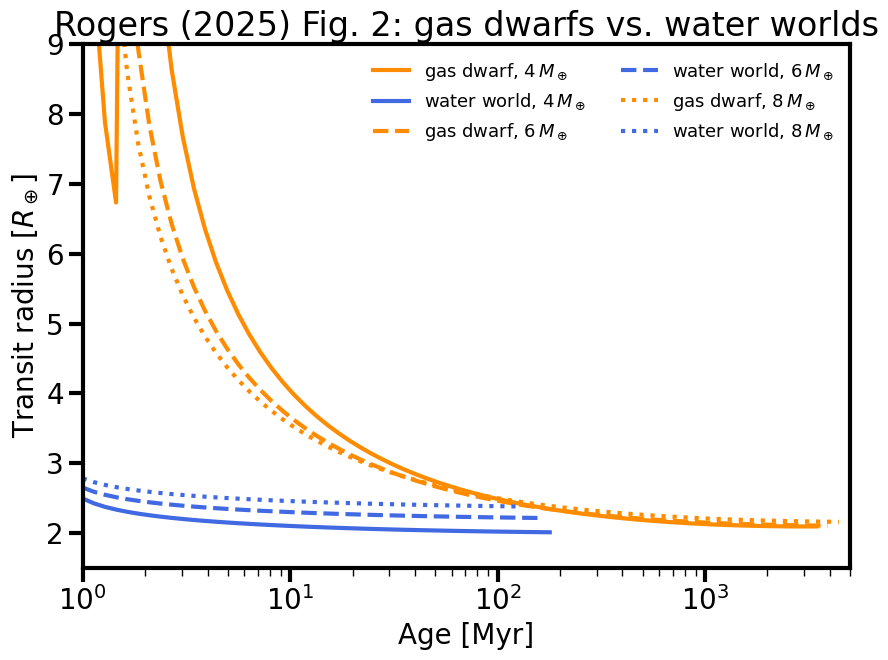

In [4]:
core_masses = [(4, '-'), (6, '--'), (8, ':')]

fig, ax = plt.subplots(figsize=(9, 7))
for Mc_e, ls in core_masses:
    # gas dwarf
    gd = make_planet(Mc_e, Teq=800.0, mu=2.35, gamma=7.0 / 5.0,
                     kappa=0.1, kind='earth', mu_c=60.0)
    a_gd, R_gd = evolve(gd, t0=1.0, t1=5000.0)
    ax.plot(a_gd, R_gd, color='darkorange', ls=ls, lw=3,
            label=f'gas dwarf, {Mc_e}' + r'$\,M_\oplus$')
    # water world
    ww = make_planet(Mc_e, Teq=800.0, mu=18.0, gamma=4.0 / 3.0,
                     kappa=0.1, kind='water', mu_c=27.0)
    a_ww, R_ww = evolve(ww, t0=1.0, t1=5000.0)
    ax.plot(a_ww, R_ww, color='royalblue', ls=ls, lw=3,
            label=f'water world, {Mc_e}' + r'$\,M_\oplus$')

ax.set_xscale('log')
ax.set_xlabel('Age [Myr]')
ax.set_ylabel(r'Transit radius [$R_\oplus$]')
ax.set_xlim(1, 5000)
ax.set_ylim(1.5, 9)
ax.legend(frameon=False, fontsize=13, ncol=2)
ax.set_title('Rogers (2025) Fig. 2: gas dwarfs vs. water worlds')
fig.tight_layout()
fig.savefig('../figures/rogers2025_fig2_gasdwarf_waterworld.png', dpi=200, bbox_inches='tight')
plt.show()

## Figure 3 — population-level predictions (Section 4)

Figure 3 shows the *underlying, unbiased* planet populations predicted by each hypothesis as a 2D occurrence density in period–radius space. Four panels: **gas dwarf** (left) vs **water world** (right), at **1–10 Gyr** (top) and **< 40 Myr** (bottom). Colour = relative probability of planet occurrence.

**Gas dwarf model (Sec. 4.2):** a single progenitor population (core mass peaked ~4 M⊕, initial envelope fraction peaked ~2%, Earth-like cores, solar H2/He envelopes with μ=2.35). XUV photoevaporation (Eq. 11, energy-limited, η≈0.15, saturated-then-declining L_XUV) strips low-mass / low-X planets to bare rocky super-Earths and carves the **radius valley** at ~1.8 R⊕ over Gyr timescales.

**Water world model (Sec. 4.3):** two separate formation channels — 35% rocky super-Earths (Earth-like, no atmosphere) and 65% steam sub-Neptunes (50% water / 50% rock cores, μ=18, steam mass fraction log-uniform 1e-5–0.1, no escape).

Orbital periods follow the smooth broken power law dN/dP ∝ 1/[(P/P0)^(-k1) + (P/P0)^(-k2)] (Eq. 18); core masses follow log-Gaussians (Eq. 19). Period/mass parameters are taken directly from the paper.

*Additional simplifications here:* the Rogers & Owen (2021) Bernstein-polynomial core / X distributions are approximated by log-normals; the photoevaporation efficiency is constant and L_XUV / T_eq use simple parametrisations instead of the Johnstone et al. (2021) + Owen & Jackson (2012) grids; the radius responds instantaneously to the current envelope mass (entropy-history coupling neglected); ~2000 planets are drawn per model (vs 1e6 in the paper). These reproduce the *structure* of Fig. 3 — the gas-dwarf radius valley, and the gas-dwarf vs water-world contrast between the young and old panels.

In [5]:
# ============================================================
#  Figure 3 - population-level predictions (Section 4)
#  Gas dwarf (XUV photoevaporation) vs water world (two channels)
# ============================================================
import time
from scipy.interpolate import RegularGridInterpolator
from scipy.stats import gaussian_kde

Msun = 1.989e33
Lsun = 3.828e33
_GLx, _GLw = np.polynomial.legendre.leggauss(80)   # fixed quadrature nodes


def _radius_track(Mc_e, Teq, mu, gamma, kappa, kind, mu_c, X, ages, gamma_c=4.0 / 3.0):
    # fast fixed-quadrature version of make_planet + evolve; returns R(ages) [R_earth]
    Mc = Mc_e * Mearth
    Rc = core_radius(Mc_e, kind)
    Menv = X * Mc
    cs2 = kB * Teq / (mu * mH)
    nab = (gamma - 1) / gamma
    RBp = G * Mc / cs2
    RB = G * Mc / (2 * cs2)
    p = 1.0 / (gamma - 1)

    def props(Rr):
        r = 0.5 * (Rr - Rc) * _GLx + 0.5 * (Rr + Rc)
        jac = 0.5 * (Rr - Rc)
        b = np.maximum(1.0 + nab * (RBp / Rr) * (Rr / r - 1.0), 1e-30)
        f = b ** p
        A = np.sum(_GLw * 4 * np.pi * r * r * f) * jac
        rho = Menv / A
        e = kB * Teq * b / (mu * mH * (gamma - 1)) - G * Mc / r
        B = np.sum(_GLw * 4 * np.pi * r * r * f * e) * jac
        Tc = Teq * (1.0 + nab * (RBp / Rr) * (Rr / Rc - 1.0))
        Ep = rho * B + Mc * kB * Tc / (mu_c * mH * (gamma_c - 1))
        L = 64 * np.pi * nab * G * Mc * sigma * Teq ** 4 / (3 * cs2 * kappa * rho)
        return Ep, rho, L

    def Rtr(Rr, rho):
        def tc(r):
            rr = rho * np.exp((G * Mc / cs2) * (1 / r - 1 / Rr))
            H = cs2 * r * r / (G * Mc)
            return kappa * rr * np.sqrt(2 * np.pi * r * H)
        if tc(Rr) < 1:
            return Rr
        try:
            return optimize.brentq(lambda r: tc(r) - 1.0, Rr, 10 * Rr)
        except Exception:
            return Rr

    def tau(Rr):
        Ep, rho, L = props(Rr)
        return abs(Ep) / L / Myr

    lo, hi = Rc * 1.02, RB * 0.999
    try:
        if tau(lo) < ages.min():
            return np.full_like(ages, Rc / Rearth)
        R0 = optimize.brentq(lambda R: tau(R) - ages.min(), lo, hi)
    except Exception:
        return np.full_like(ages, Rc / Rearth)

    def dEpdR(Rr):
        h = Rr * 1e-4
        return (props(Rr + h)[0] - props(Rr - h)[0]) / (2 * h)

    sol = integrate.solve_ivp(lambda t, y: [-props(y[0])[2] * Myr / dEpdR(y[0])],
                              [ages.min(), ages.max()], [R0], t_eval=ages,
                              rtol=1e-4, atol=1e4, max_step=500)
    out = np.array([Rtr(Rr, props(Rr)[1]) / Rearth for Rr in sol.y[0]])
    if len(out) < len(ages):
        out = np.concatenate([out, np.full(len(ages) - len(out), out[-1])])
    return np.maximum(out, Rc / Rearth)


_Mc_grid = np.array([1, 2, 3, 5, 8, 13, 20.])
_X_grid = np.array([1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1])
_Teq_grid = np.array([300, 550, 800, 1100.])
_ages = np.logspace(0, 4.0, 32)


def _build_interp(mu, gamma, kind, mu_c):
    tab = np.zeros((len(_Mc_grid), len(_X_grid), len(_Teq_grid), len(_ages)))
    for i, Mc in enumerate(_Mc_grid):
        for j, X in enumerate(_X_grid):
            for k, Te in enumerate(_Teq_grid):
                tab[i, j, k] = np.log10(_radius_track(Mc, Te, mu, gamma, 0.1, kind, mu_c, X, _ages))
    it = RegularGridInterpolator((np.log10(_Mc_grid), np.log10(_X_grid), _Teq_grid, np.log10(_ages)),
                                 tab, bounds_error=False, fill_value=None)

    def R(Mc, X, Teq, age):
        q = [np.log10(np.clip(Mc, 1, 20)), np.log10(np.clip(X, 1e-4, 0.3)),
             np.clip(Teq, 300, 1100), np.log10(np.clip(age, 1, 1e4))]
        return 10 ** float(it(q))
    return R


t0 = time.time()
R_gd_pop = _build_interp(2.35, 7.0 / 5.0, 'earth', 60.0)   # gas dwarf
R_ww_pop = _build_interp(18.0, 4.0 / 3.0, 'water', 27.0)   # water-world sub-Neptune (steam)
print('radius interpolators built in %.1f s' % (time.time() - t0))


def Teq_orbit(P_day, Mstar):
    a = (G * Mstar * (P_day * 86400.0) ** 2 / (4 * np.pi ** 2)) ** (1 / 3.0)
    Lbol = Lsun * (Mstar / Msun) ** 4
    return (Lbol / (16 * sigma * np.pi * a * a)) ** 0.25, a


def L_xuv(age_myr, Mstar):
    # saturated, then t^-1.5 decline (Johnstone et al. 2021-like parametrisation)
    Lbol = Lsun * (Mstar / Msun) ** 4
    Lsat = 10 ** -3.5 * Lbol
    tsat = 100.0
    return Lsat if age_myr < tsat else Lsat * (age_myr / tsat) ** -1.5


def draw_period(n, P0, k1, k2, rng):
    # smooth broken power law, Eq. 18
    P = np.logspace(0, 2, 500)
    w = 1.0 / ((P / P0) ** (-k1) + (P / P0) ** (-k2))
    w /= w.sum()
    return rng.choice(P, n, p=w)


# observation-epoch sampling per age group (Myr).
# 'old'  : 1-10 Gyr  (paper's old panel)
# 'young': < 40 Myr  (paper's young panel)
# 'le100': <= 100 Myr  -> diagnostic bin matched to the young-planet sample
# 'mid'  : 100-700 Myr -> bulk of the young-planet sample
def draw_tobs(epoch, td, rng):
    if epoch == 'old':
        return rng.uniform(1000, 10000)
    if epoch == 'le100':
        return rng.uniform(td, 100)
    if epoch == 'mid':
        return rng.uniform(100, 700)
    return rng.uniform(td, 40)   # 'young'


def evolve_gd(Mc_e, X0, P, Mstar, tdisc, tobs, eta=0.15):
    # energy-limited XUV photoevaporation, Eq. 11
    Mc = Mc_e * Mearth
    Teq, a = Teq_orbit(P, Mstar)
    Menv = X0 * Mc
    ts = np.logspace(np.log10(tdisc), np.log10(tobs), 50)
    for n in range(len(ts) - 1):
        X = Menv / Mc
        if X < 1e-4:
            return core_radius(Mc_e, 'earth') / Rearth
        Rp = R_gd_pop(Mc_e, X, Teq, ts[n]) * Rearth
        Mdot = eta * (L_xuv(ts[n], Mstar) / (4 * np.pi * a * a)) * (np.pi * Rp ** 3 / (G * Mc))
        Menv -= Mdot * (ts[n + 1] - ts[n]) * Myr
        if Menv < Mc * 1e-4:
            return core_radius(Mc_e, 'earth') / Rearth
    return R_gd_pop(Mc_e, Menv / Mc, Teq, tobs)


rng = np.random.default_rng(42)
N = 2000


def gas_dwarf_population(epoch):
    # core mass peaked ~4 Mearth, initial X peaked ~2% (Rogers & Owen 2021 minimal model)
    Mc_e = np.clip(np.exp(rng.normal(np.log(4.0), 0.35, N)), 1, 20)
    X0 = np.clip(np.exp(rng.normal(np.log(0.02), 0.5, N)), 1e-3, 0.3)
    P = draw_period(N, 5.5, 2.3, 0.0, rng)
    Ms = np.clip(rng.normal(1.0, 0.3, N), 0.5, 1.6) * Msun
    R = np.empty(N)
    for i in range(N):
        td = rng.uniform(3, 10)
        tobs = draw_tobs(epoch, td, rng)
        R[i] = evolve_gd(Mc_e[i], X0[i], P[i], Ms[i], td, tobs)
    return P, R


def water_world_population(epoch):
    # 35% rocky super-Earths + 65% steam sub-Neptunes, no escape
    n_se = int(0.35 * N)
    n_sn = N - n_se
    Ms = np.clip(rng.normal(1.0, 0.3, N), 0.5, 1.6) * Msun
    Mse = np.clip(10 ** rng.normal(np.log10(3.0), 0.35, n_se), 0.5, 20)
    Pse = draw_period(n_se, 4.5, 2.0, -0.5, rng)
    Rse = core_radius(Mse, 'earth') / Rearth
    Msn = np.clip(10 ** rng.normal(np.log10(10.0), 0.30, n_sn), 1, 20)
    Psn = draw_period(n_sn, 8.5, 2.5, 0.1, rng)
    Xsn = 10 ** rng.uniform(np.log10(1e-5), np.log10(0.1), n_sn)
    Rsn = np.empty(n_sn)
    for i in range(n_sn):
        td = rng.uniform(3, 10)
        tobs = draw_tobs(epoch, td, rng)
        Teq, _ = Teq_orbit(Psn[i], Ms[i + n_se])
        Rsn[i] = R_ww_pop(Msn[i], Xsn[i], Teq, tobs)
    return np.concatenate([Pse, Psn]), np.concatenate([Rse, Rsn])


t0 = time.time()
# 'old'/'young' kept for the 4-panel figure; 'le100'/'mid' for the data comparison
epochs = ['old', 'young', 'le100', 'mid']
pops = {}
for ep in epochs:
    pops[('gd', ep)] = gas_dwarf_population(ep)
    pops[('ww', ep)] = water_world_population(ep)
print('populations synthesised in %.1f s' % (time.time() - t0))

/tmp/ipykernel_1742261/2381862791.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  rho = Menv / A
/tmp/ipykernel_1742261/2381862791.py:35: RuntimeWarning: invalid value encountered in scalar multiply
  Ep = rho * B + Mc * kB * Tc / (mu_c * mH * (gamma_c - 1))
/tmp/ipykernel_1742261/2381862791.py:41: RuntimeWarning: invalid value encountered in scalar multiply
  rr = rho * np.exp((G * Mc / cs2) * (1 / r - 1 / Rr))


radius interpolators built in 13.2 s


/tmp/ipykernel_1742261/2381862791.py:94: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return 10 ** float(it(q))


populations synthesised in 63.6 s


In [ ]:
from pathlib import Path
from astroquery.ipac.nexsci.nasa_exoplanet_archive import NasaExoplanetArchive
import pandas as pd
from uncertainties import ufloat

def get_nexsci_data(table_name="ps", clobber=False, outdir="../data"):
    """
    ps: self-consistent set of parameters
    pscomppars: a more complete, though not necessarily self-consistent set of parameters
    """
    url = "https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html"
    print("Column definitions: ", url)
    fp = Path(outdir,f"nexsci_{table_name}.csv")
    if not fp.exists() or clobber:
        print(f"Downloading NExSci {table_name} table...")
        nexsci_tab = NasaExoplanetArchive.query_criteria(table=table_name, 
                                                         # where="discoverymethod like 'Transit'"
                                                        )
        df_nexsci = nexsci_tab.to_pandas()
        df_nexsci.to_csv(fp, index=False)
        print("Saved: ", fp)
    else:
        df_nexsci = pd.read_csv(fp)
        print("Loaded: ", fp)
    return df_nexsci

In [ ]:
df_nexsci = get_nexsci_data(table_name="ps", clobber=False)
df_nexsci.head()

In [8]:
# get values from default references
idx = df_nexsci['default_flag'] == 1
all_hostnames = df_nexsci[idx].hostname.unique()
len(all_hostnames)

4716

In [9]:
#TOI-1136
idx = df_nexsci[df_nexsci.hostname=="TOI-1136"][df_nexsci[df_nexsci.hostname=="TOI-1136"].pl_refname.str.contains("Dai")].index
df_nexsci.loc[idx,'default_flag']=1

In [10]:
import astropy.units as u

# get only transiting planets
df_nexsci['pl_rade'] = df_nexsci['pl_radj']*u.Rjup.to(u.Rearth)

# filter data
idx = (df_nexsci.pl_orbper>0) & \
        (df_nexsci.pl_rade>0) & \
        (df_nexsci.st_mass>0) & \
        (df_nexsci.discoverymethod.isin(['Transit','Radial Velocity'])) & \
        (df_nexsci['default_flag'] == 1)
df = df_nexsci[idx]
df.shape

(3833, 357)

In [11]:
import pandas as pd

df_hosts = pd.read_csv("/ut2/jerome/github/research/project/TOI-6715/data/young_validated_planets_TOIs - validated_hosts.csv", 
                       comment='#', skiprows=[1]).dropna(subset=['Host'],
                                             )
df_hosts = df_hosts.iloc[:68]
df_hosts = df_hosts.reset_index(drop=True)
df_hosts.shape

(68, 38)

In [12]:
df_hosts['hostname'] = df_hosts.Host.str.lower().str.replace(' ', '')
young_hostnames = df_hosts['hostname'].reset_index(drop=True)
df = df.copy()
df['hostname'] = df['hostname'].str.lower().str.replace(' ', '')
idx = df['hostname'].isin(young_hostnames)
df_planets = df[idx]
df_planets.shape

(105, 357)

In [13]:
df_hosts['Age_lower'] = df_hosts['Age'].apply(lambda x: str(x).split('-')[0]).astype(float).values
df_hosts['Age_upper'] = df_hosts['Age'].apply(lambda x: str(x).split('-')[1]).astype(float).values

In [34]:
import astropy.units as u

# TIC*1445
target = {'pl_orbper': (3.272052, 1e-05), #best['b_period'],
          'pl_rade': (5.7, 0.7), #(Rp_samples.median(), Rp_samples.std())
           'name': 'TIC*1445b'
}

# TOI-6715
target2 = {'pl_orbper': (2.8625896500316537, 3.263991441179825e-06),
           'pl_rade': (4.5, 0.3),
           'name': 'TOI-6715b'
          }

# TOI-????
# target3 = {'pl_orbper': (3.16, 1e-05),
#  'pl_rade': (8.67, 0.1)}

# TOI-5973
target4 = {'pl_orbper': (3.16, 1e-05),
           'pl_rade': (8.5, #(2.17026355*u.Rjup.to(u.Rearth),
             2.5e-7*u.Rjup.to(u.Rearth)),
           'name': 'TOI-5973b'
          }

target5 = {'pl_orbper': (0.3052608, 5e-7),
           'pl_rade': (1.4, 0.17),
           'name': 'TOI-6940b'
          }

target6 = {'pl_orbper': (8.0387972, 0.0000287),
           'pl_rade': (2.25604, 0.174709),
           'name': 'TOI-5169b'
          }

# 
target7 = {'pl_orbper': (6.1841876, 0.0000080),
           'pl_rade': (2.1, 0.12),
           'name': 'TOI-5734b'
          }

special = [#'toi-5734', #Morello et al. 2026
           'hip67522', #Barber et al. 2024
           'tic434398831' #Vach et al. 2025
          ]

/tmp/ipykernel_1742261/3496387324.py:61: UserWarning: The following kwargs were not used by contour: 'shading'
  pc = ax.contourf(10 ** XX, 10 ** YY, ZZ, cmap=cmap, shading='auto')


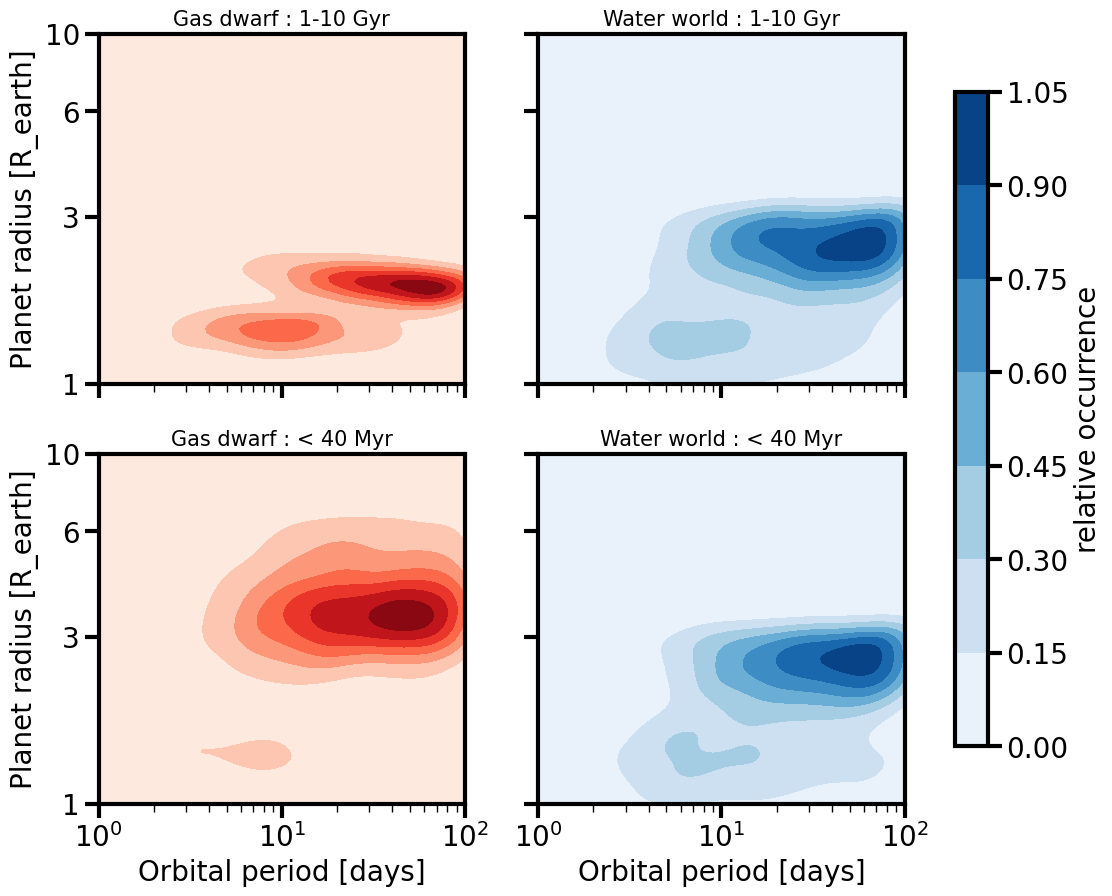

In [35]:
from matplotlib.ticker import ScalarFormatter, NullLocator

def empirical_neptune_desert_boundary_loglog():
    x_tw_low = np.linspace(-0.30, np.log10(2.97), 100)
    x_tw_up = np.linspace(np.log10(2.97), 0.120,  100)
    y_tw_up = -0.43 * x_tw_up + 1.14
    y_tw_low = +0.55 * x_tw_low + 0.36
    
    # print(x_tw_low,y_tw_low)
    # print(x_tw_up,y_tw_up)
    
    x1 = np.tile(-0.30,100)
    y1= np.linspace(-0.07,0.191,100)
    
    x2 = np.tile(0.12,100)
    y2 = np.linspace(1.0884,1.20,100)

    x  = np.concatenate([x1,x_tw_low,x_tw_up,x2])
    y = np.concatenate([y1,y_tw_low,y_tw_up,y2])
    return x,y

def overplot_neptune_desert(ax, **kw):
    x, y = empirical_neptune_desert_boundary_loglog()
    style = dict(color='k', lw=2, ls='--', alpha=0.9, zorder=5)
    style.update(kw)
    ax.plot(10**x, 10**y, **style)          # period [days], radius [R_earth]

def vaneylen_model_loglog(x): 
    """
    period-radius: log10R = mlog10P + a
    
    https://ui.adsabs.harvard.edu/abs/2018MNRAS.479.4786V/abstract
    """
    y1 = x*(-0.09+0.02)+(0.37+0.04)
    y2 = x*(-0.09-0.04)+(0.37-0.02)
    return y1, y2
    
def overplot_radius_valley(ax, **kw):
    x = np.linspace(0, 2, 100)          # log10 P over the panel range (1–100 d)
    y1, y2 = vaneylen_model_loglog(x)
    # P = 10**x
    # ax.plot(P, 10**y1, color='w', ls='--', lw=1.3, alpha=0.8, zorder=5)
    # ax.plot(P, 10**y2, color='w', ls='--', lw=1.3, alpha=0.8, zorder=5)
    # ax.fill_between(P, 10**y1, 10**y2, color='w', alpha=0.12, zorder=4)  # uncertainty band
    ax.plot(10**x, 10**(-0.09 * x + 0.37),  # period [days], radius [R_earth]
          color='k', ls=':', lw=1.3, alpha=0.85, zorder=5)
    
# 2D occurrence density in period-radius space (KDE), four panels
def panel_density(ax, P, R, title, cmap):    
    x = np.log10(P)
    xs = np.linspace(0, 2, 110)

    y = np.log10(R)
    ys = np.linspace(0, np.log10(10), 110)          # log10 R grid
    XX, YY = np.meshgrid(xs, ys)
    kde = gaussian_kde(np.vstack([x, y]))
    ZZ = kde(np.vstack([XX.ravel(), YY.ravel()])).reshape(XX.shape)
    ZZ /= ZZ.max()
    
    # pc = ax.pcolormesh(10 ** XX, YY, ZZ, cmap=cmap, shading='auto')
    pc = ax.contourf(10 ** XX, 10 ** YY, ZZ, cmap=cmap, shading='auto')
    
    ax.set_xscale('log')
    ax.set_xlim(1, 100)
    ax.set_yscale('log')
    ax.set_ylim(1, 10)
    ax.set_title(title, fontsize=15)
    ax.set_yticks([1, 3, 6, 10])
    ax.yaxis.set_minor_locator(NullLocator())        # kill the 2,4,5,7,8,9 minor ticks
    ax.yaxis.set_major_formatter(ScalarFormatter())  # show 1,3,6,10 not 10^0 etc.
    ax.ticklabel_format(axis='y', style='plain')     # belt-and-suspenders, no sci notation
    return pc


fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
panel_density(axes[0, 0], *pops[('gd', 'old')], 'Gas dwarf : 1-10 Gyr', cmap='Reds')
panel_density(axes[0, 1], *pops[('ww', 'old')], 'Water world : 1-10 Gyr', cmap='Blues')
panel_density(axes[1, 0], *pops[('gd', 'young')], 'Gas dwarf : < 40 Myr', cmap='Reds')
pc = panel_density(axes[1, 1], *pops[('ww', 'young')], 'Water world : < 40 Myr', cmap='Blues')
for ax in axes[:, 0]:
    ax.set_ylabel('Planet radius [R_earth]')
    # ax.set_ylabel('Transit radius [R_earth]')
for ax in axes[1, :]:
    ax.set_xlabel('Orbital period [days]')
fig.colorbar(pc, ax=axes, label='relative occurrence', shrink=0.85)
# fig.suptitle('Rogers (2025) Fig. 3: population-level predictions', fontsize=18)
fig.savefig('../figures/rogers2025_fig3_population.png', dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11), sharex=True, sharey=True)
for row, (epoch, age_range, lbl) in enumerate(age_bins):
    panel_density(axes[row, 0], *pops[('gd', 'young')], 'Gas dwarf : < 40 Myr',
                  cmap='Greens', plot_data=True, age_range=age_range)
    panel_density(axes[row, 1], *pops[('wd', 'young')], 'Water world : < 40 Myr',
                  cmap='Purples', plot_data=True, age_range=age_range)

In [ ]:
from matplotlib.ticker import ScalarFormatter, NullLocator
import matplotlib.patheffects as pe

# "Our Work" highlighted targets (no published age -> shown only on the youngest panel)
our_work_targets = [#(target, 'C3'), 
                    (target2, 'C3'), #(target4, 'C3'),
                    #(target5, 'C0'), (target6, 'C0'), (target7, 'C0')
                   ]


def overplot_young_planets(ax, age_range=None):
    """Overlay the matched young-planet sample, optionally restricted to a host
    age bin [age_range = (lo, hi) in Myr, compared against the host age midpoint]."""
    x, y = 'pl_orbper', 'pl_rade'
    seen = set()
    for xx, yy, n in zip(df_planets[x], df_planets[y], df_planets['hostname']):
        sub = df_hosts[young_hostnames == n]
        if len(sub) == 0:                      # no host match -> skip
            continue
        d = sub.iloc[0]
        try:
            amid = 0.5 * (float(d.Age_lower) + float(d.Age_upper))
        except Exception:
            continue
        if age_range is not None and not (age_range[0] <= amid < age_range[1]):
            continue                            # outside this panel's age bin
        color, lbl = ('C3', 'age<100Myr') if amid < 100 else ('C0', '100Myr<age<1Gyr')
        # marker = '*' if n in special else 'o'
        # s = 13 if n in special else 8
        # z = 100 if n in special else 10
        marker = 'o'
        s = 8
        z = 10
        ax.plot(xx, yy, marker, ms=s, mec='w', c=color, zorder=z,
                label=lbl if lbl not in seen else None)
        seen.add(lbl)

    # our-work targets: plot once, only on the youngest bin (they are <100 Myr)
    if age_range is not None and age_range[0] < 100:
        for t, c in our_work_targets:
            ax.scatter(t[x], t[y], marker='*', s=200, color=c, edgecolors='w', zorder=110)
            ax.annotate(t['name'], (t[x][0], t[y][0]),
                          xytext=(6, 6), textcoords='offset points',
                          fontsize=8, color=c, zorder=111,
                          path_effects=[pe.withStroke(linewidth=2, foreground='w')])

def empirical_neptune_desert_boundary_loglog():
    x_tw_low = np.linspace(-0.30, np.log10(2.97), 100)
    x_tw_up = np.linspace(np.log10(2.97), 0.120,  100)
    y_tw_up = -0.43 * x_tw_up + 1.14
    y_tw_low = +0.55 * x_tw_low + 0.36

    x1 = np.tile(-0.30, 100)
    y1 = np.linspace(-0.07, 0.191, 100)
    x2 = np.tile(0.12, 100)
    y2 = np.linspace(1.0884, 1.20, 100)

    x = np.concatenate([x1, x_tw_low, x_tw_up, x2])
    y = np.concatenate([y1, y_tw_low, y_tw_up, y2])
    return x, y


def overplot_neptune_desert(ax, **kw):
    x, y = empirical_neptune_desert_boundary_loglog()
    style = dict(color='k', lw=2, ls='--', alpha=0.9, zorder=5)
    style.update(kw)
    ax.plot(10 ** x, 10 ** y, **style)          # period [days], radius [R_earth]


def overplot_radius_valley(ax, **kw):
    x = np.linspace(0, 2, 100)                   # log10 P over the panel range (1-100 d)
    ax.plot(10 ** x, 10 ** (-0.09 * x + 0.37),   # Van Eylen et al. 2018
            color='k', ls=':', lw=1.3, alpha=0.85, zorder=5)


# 2D occurrence density in period-radius space (KDE)
def panel_density(ax, P, R, title, cmap, plot_data=False, age_range=None):
    ax.set_xscale('log')
    ax.set_yscale('log')

    xs = np.linspace(0, 2, 110)                  # log10 P  (1-100 d)
    ys = np.linspace(0, np.log10(10), 110)       # log10 R  (1-10 R_earth)
    XX, YY = np.meshgrid(xs, ys)
    kde = gaussian_kde(np.vstack([np.log10(P), np.log10(R)]))
    ZZ = kde(np.vstack([XX.ravel(), YY.ravel()])).reshape(XX.shape)
    ZZ /= ZZ.max()

    pc = ax.contourf(10 ** XX, 10 ** YY, ZZ, levels=np.linspace(0, 1, 11), cmap=cmap)

    overplot_neptune_desert(ax)
    overplot_radius_valley(ax)
    if plot_data:
        overplot_young_planets(ax, age_range=age_range)

    ax.set_xlim(1, 100)
    ax.set_ylim(1, 8)
    ax.set_title(title, fontsize=15)
    ax.set_yticks([1, 2, 4, 6, 8])
    ax.yaxis.set_minor_locator(NullLocator())
    ax.yaxis.set_major_formatter(ScalarFormatter())
    ax.ticklabel_format(axis='y', style='plain')
    return pc


# rows = sample-matched age bins; columns = gas dwarf vs water world
age_bins = [('le100', (0, 100),   r'$\leq$100 Myr'),
            ('mid',   (100, 1000), '100-1000 Myr')]

fig, axes = plt.subplots(2, 2, figsize=(12, 12), sharex=True, sharey=True)
for row, (epoch, age_range, lbl) in enumerate(age_bins):
    panel_density(axes[row, 0], *pops[('gd', epoch)], f'Gas dwarf : {lbl}',
                  cmap='Greens', plot_data=True, age_range=age_range)
    panel_density(axes[row, 1], *pops[('ww', epoch)], f'Water world : {lbl}',
                  cmap='Purples', plot_data=True, age_range=age_range)

for ax in axes[:, 0]:
    ax.set_ylabel(r'Planet radius [R$_{\oplus}$]')
for ax in axes[1, :]:
    ax.set_xlabel('Orbital period [days]')
# axes[0, 0].legend(frameon=False, fontsize=11, loc='upper right')
fig.tight_layout()
fig.savefig('../figures/rogers2025_fig_data_vs_model_agebins.png', dpi=200, bbox_inches='tight')
plt.show()

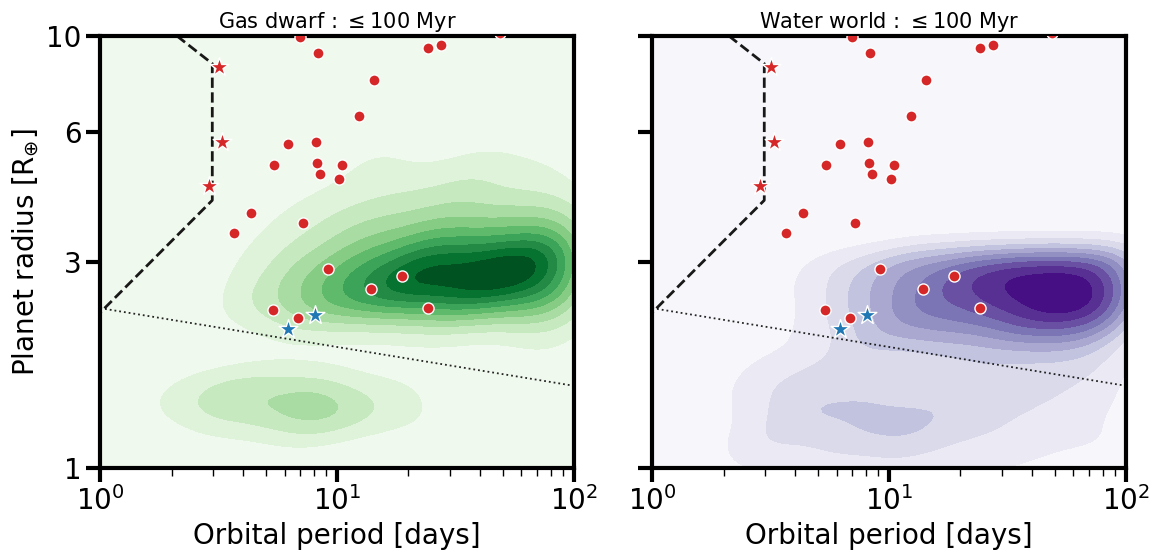

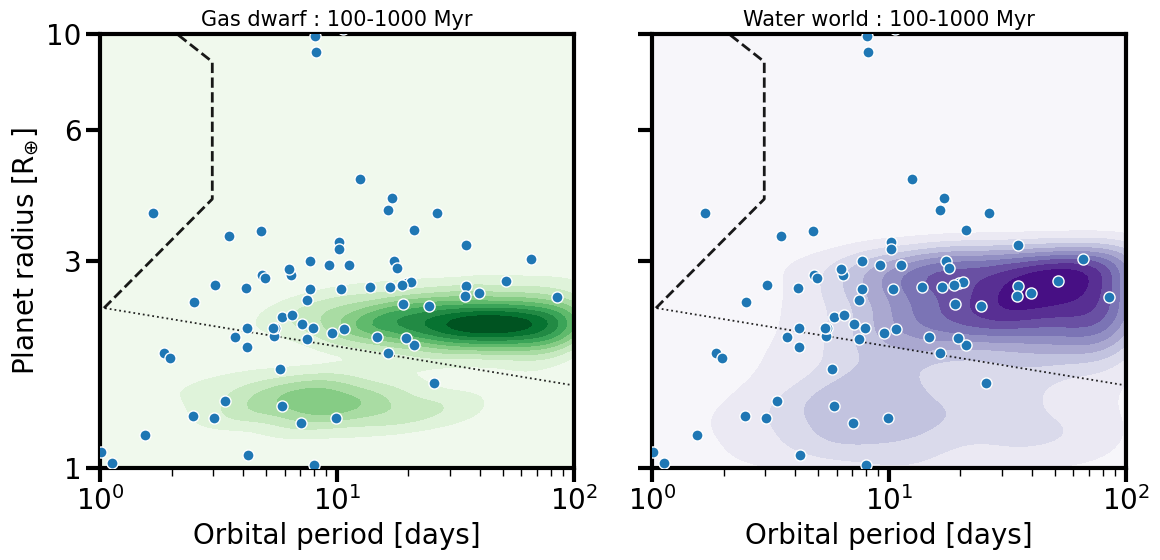

In [51]:
for epoch, age_range, lbl in age_bins:
      fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
      panel_density(axes[0], *pops[('gd', epoch)], f'Gas dwarf : {lbl}',
                    cmap='Greens', plot_data=True, age_range=age_range)
      panel_density(axes[1], *pops[('ww', epoch)], f'Water world : {lbl}',
                    cmap='Purples', plot_data=True, age_range=age_range)
      axes[0].set_ylabel(r'Planet radius [R$_{\oplus}$]')
      for ax in axes:
          ax.set_xlabel('Orbital period [days]')
      # axes[0].legend(frameon=False, fontsize=11, loc='upper right')
      fig.tight_layout()
      tag = lbl.replace(' ', '').replace('<=', 'le').replace('-', '_')  # e.g. le100Myr
      fig.savefig(f'../figures/rogers2025_data_vs_model_{tag}.png', dpi=200, bbox_inches='tight')
      plt.show()

In Figures 1 and 2 the envelope mass is fixed ($\dot M=0$, so $X$ is constant). What evolves is the planet's internal energy / entropy. The only active evolution equation is

  $$\frac{dE_{\rm p}}{dt}=-L_{\rm rad}.$$

  The planet starts hot and puffy (set by the initial condition $\tau_{\rm cool}=$ age). It continuously radiates energy away at its radiative–convective boundary at rate $L_{\rm rad}>0$, so $E_{\rm p}$ decreases
  monotonically. As the envelope loses energy:

  - its temperature drops (lower interior adiabat / entropy),
  - the gas scale height $H = c_{\rm s}^2 r^2/GM_{\rm c} = k_{\rm B}T,r^2/(\mu m_{\rm H} GM_{\rm c})$ shrinks because $T$ falls,
  - the same fixed envelope mass now sits in a smaller volume — $\rho_{\rm rcb}$ rises and $R_{\rm rcb}$ (and the transit radius) move inward.

  So the radius shrinks at constant mass purely because the planet is cooling and contracting (Kelvin–Helmholtz contraction). The envelope is supported by its thermal pressure; remove thermal energy and it
  deflates.

  This is exactly why mean molecular weight matters so much at young ages (Fig. 1): $H\propto 1/\mu$, so a low-$\mu$ (H₂/He) envelope is hugely inflated when hot and then contracts a lot as it cools, while a
  high-$\mu$ (steam) envelope has a small scale height to begin with and barely changes. And it's why gas dwarfs and water worlds (Fig. 2) start very different in size but converge at Gyr ages — both have
  radiated away most of their formation heat and settled toward their cold, mass-determined radius.

  Contrast with Figure 3, where mass loss (XUV photoevaporation) is switched on: there the radius can change for a second, distinct reason — actual stripping of envelope mass — which is what carves the radius
  valley.

## Takeaways

* **Fig. 1**: at $\lesssim100$ Myr the transit radius is a strong function of bulk mean molecular weight — low-$\mu$ (H$_2$/He) envelopes are dramatically inflated, high-$\mu$ (steam) envelopes barely move. The spread shrinks with age as planets cool and contract.
* **Fig. 2**: gas dwarfs and water worlds of the same core mass are **degenerate at Gyr ages** but **diverge strongly at young ages** — hence young transiting planets (e.g. in stellar clusters) break the gas-dwarf / water-world degeneracy. Radius is nearly independent of core mass ($R_{\rm p}\propto X^{2/3}M_{\rm c}^{-1/3}$, Eq. 14).

Absolute radii depend on the (here simplified) opacity, core mass-radius relation, and initial entropy; the *relative* behaviour that drives the paper's argument is robust to these choices.